# CREATE THE SCENARIO

**TRANSACTION GENERATION PROCESS**

The simulation will consist of five main steps:
1. **Generation of customer profiles**:
    - Every customer is different in their spending habits. This will be simulated by defining some properties for each customer.
    - The main properties will be their geographical location, their spending frequency, and their spending amounts.
    - The customer properties will be represented as a table, referred to as the customer profile table.
2. **Generation of terminal profiles**: 
    - Terminal properties will simply consist of a geographical location.
    - The terminal properties will be represented as a table, referred to as the terminal profile table.
3. **Association of customer profiles to terminals**:
    - We will assume that customers only make transactions on terminals that are within a radius of *r* of their geographical locations. This makes the simple assumption that a customer only makes transactions on terminals that are geographically close to their location. 
    - This step will consist of adding a feature *list_terminals* to each customer profile, that contains the set of terminals that a customer can use.
4. **Generation of transactions**: 
    - The simulator will loop over the set of customer profiles, and generate transactions according to their properties (spending frequencies and amounts, and available terminals). This will result in a table of transactions.
5. **Generation of fraud scenarios**: 
    - This last step will label the transactions as legitimate or genuine. This will be done by following three different fraud scenarios.

The transaction generation process is illustrated below.

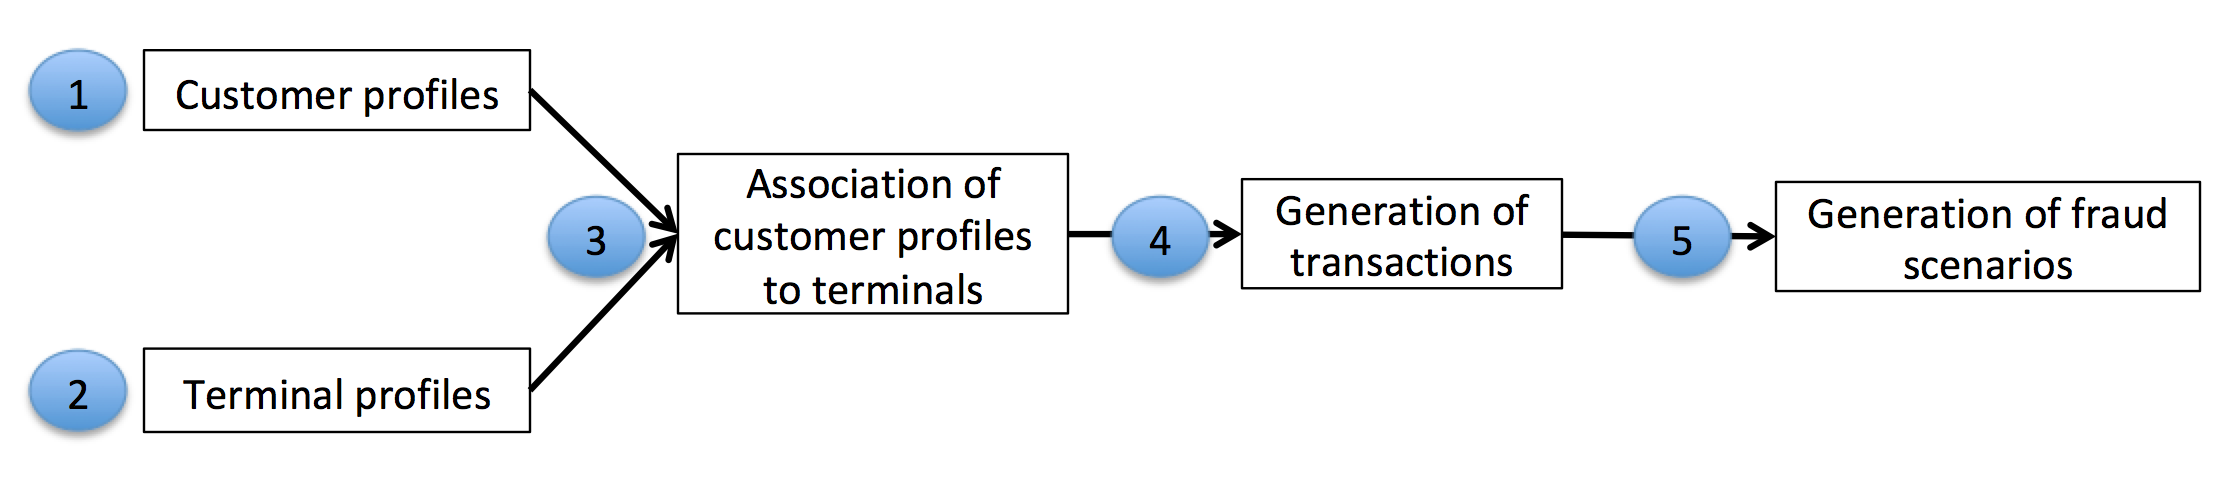

Now in the sub cells we report the Python code used to generate our scenario 

## CONFIGURATION

In [ ]:
# pip install numpy 
# pip install pandas

In [ ]:
# import
import os

import numpy as np
import pandas as pd

import time

import random

## GENERATING THE CUSTOMER TABLE

Define the function: *generate_customer_profile_table*

The *generate_customer_profiles_table* function provides an implementation for generating a table of customer profiles.
- It takes as input the number of customers for which to generate a profile and a random state for reproducibility.
- It returns a DataFrame containing the properties for each customer.

In [ ]:
def generate_customer_profiles_table(n_customers, random_state=0):

    np.random.seed(random_state)

    customer_id_properties=[]

    # Generate customer properties from random distributions
    for customer_id in range(n_customers):

        x_customer_id = np.random.uniform(0,100)
        y_customer_id = np.random.uniform(0,100)

        mean_amount = np.random.uniform(5,100) # Arbitrary (but sensible) value
        std_amount = mean_amount/2 # Arbitrary (but sensible) value

        mean_nb_tx_per_day = np.random.uniform(0,4) # Arbitrary (but sensible) value

        customer_id_properties.append([customer_id,
                                      x_customer_id, y_customer_id,
                                      mean_amount, std_amount,
                                      mean_nb_tx_per_day])

    customer_profiles_table = pd.DataFrame(customer_id_properties, columns=['CUSTOMER_ID',
                                                                      'x_customer_id', 'y_customer_id',
                                                                      'mean_amount', 'std_amount',
                                                                      'mean_nb_tx_per_day'])

    return customer_profiles_table

## GENERATING THE TERMINAL TABLE

Define the function: *generate_terminal_profile_table*

The *generate_terminal_profiles_table* function provides an implementation for generating a table of terminal profiles.
- It takes as input the number of terminals for which to generate a profile and a random state for reproducibility. 
- It returns a DataFrame containing the properties for each terminal.

In [ ]:
def generate_terminal_profiles_table(n_terminals, random_state=0):

    np.random.seed(random_state)

    terminal_id_properties=[]

    # Generate terminal properties from random distributions
    for terminal_id in range(n_terminals):

        x_terminal_id = np.random.uniform(0,100)
        y_terminal_id = np.random.uniform(0,100)

        terminal_id_properties.append([terminal_id,
                                      x_terminal_id, y_terminal_id])

    terminal_profiles_table = pd.DataFrame(terminal_id_properties, columns=['TERMINAL_ID',
                                                                      'x_terminal_id', 'y_terminal_id'])

    return terminal_profiles_table

## ASSOCIATION OF CUSTOMER PROFILES TO TERMINALS

Define the function: *get_list_terminals_within_radious* and compute the list of available terminals for each customer

Let us first write a function, called *get_list_terminals_within_radius*, which finds these terminals for a customer profile. 
- The function will take as input a customer profile (any row in the customer profiles table), an array that contains the geographical location of all terminals, and the radius *r*.
- It will return the list of terminals within a radius of *r* for that customer.

In [ ]:
def get_list_terminals_within_radius(customer_profile, x_y_terminals, r):

    # Use numpy arrays in the following to speed up computations

    # Location (x,y) of customer as numpy array
    x_y_customer = customer_profile[['x_customer_id','y_customer_id']].values.astype(float)

    # Squared difference in coordinates between customer and terminal locations
    squared_diff_x_y = np.square(x_y_customer - x_y_terminals)

    # Sum along rows and compute suared root to get distance
    dist_x_y = np.sqrt(np.sum(squared_diff_x_y, axis=1))

    # Get the indices of terminals which are at a distance less than r
    available_terminals = list(np.where(dist_x_y<r)[0])

    # Return the list of terminal IDs
    return available_terminals

## GENERATING THE TRANSACTIONS

Define the function: *generate_transaction_table*

- The transaction generation will be done by a function generate_transactions_table that takes as input a customer profile, a starting date, and a number of days for which to generate transactions.
- It will return a table of transactions, which follows the format presented above (without the transaction label, which will be added in fraud scenarios generation).

In [ ]:
# run the code with the dataset parameter before this one
def generate_transactions_table(customer_profile, start_date, nb_days):

    customer_transactions = []

    random.seed(int(customer_profile.CUSTOMER_ID))
    np.random.seed(int(customer_profile.CUSTOMER_ID))

    # For all days
    for day in range(nb_days):

        # Random number of transactions for that day
        nb_tx = np.random.poisson(customer_profile.mean_nb_tx_per_day)

        # If nb_tx positive, let us generate transactions
        if nb_tx>0:

            for tx in range(nb_tx):

                # Time of transaction: Around noon, std 20000 seconds. This choice aims at simulating the fact that
                # most transactions occur during the day.
                time_tx = int(np.random.normal(86400/2, 20000))

                # If transaction time between 0 and 86400, let us keep it, otherwise, let us discard it
                if (time_tx>0) and (time_tx<86400):

                    # Amount is drawn from a normal distribution
                    amount = np.random.normal(customer_profile.mean_amount, customer_profile.std_amount)

                    # If amount negative, draw from a uniform distribution
                    if amount<0:
                        amount = np.random.uniform(0,customer_profile.mean_amount*2)

                    amount=np.round(amount,decimals=2)

                    if len(customer_profile.available_terminals)>0:

                        terminal_id = random.choice(customer_profile.available_terminals)

                        customer_transactions.append([time_tx+day*86400, day,
                                                      customer_profile.CUSTOMER_ID,
                                                      terminal_id, amount])

    customer_transactions = pd.DataFrame(customer_transactions, columns=['TX_TIME_SECONDS', 'TX_TIME_DAYS', 'CUSTOMER_ID', 'TERMINAL_ID', 'TX_AMOUNT'])

    if len(customer_transactions)>0:
        customer_transactions['TX_DATETIME'] = pd.to_datetime(customer_transactions["TX_TIME_SECONDS"], unit='s', origin=start_date)
        customer_transactions=customer_transactions[['TX_DATETIME','CUSTOMER_ID', 'TERMINAL_ID', 'TX_AMOUNT','TX_TIME_SECONDS', 'TX_TIME_DAYS']]

    return customer_transactions



## SCALING UP TO A LARGER DATASET

Define the function: *generate_dataset*

Let us write a generate_dataset function, that will take care of running all the previous steps.
- It will take as inputs the number of desired customers, terminals and days, as well as the starting date and the radius r
- It returns the generated customer and terminal profiles table, and the DataFrame of transactions.

In [ ]:
def generate_dataset(n_customers, n_terminals, nb_days, start_date, r):

    start_time=time.time()
    customer_profiles_table = generate_customer_profiles_table(n_customers, random_state = 0)
    print("Time to generate customer profiles table: {0:.2}s".format(time.time()-start_time))

    start_time=time.time()
    terminal_profiles_table = generate_terminal_profiles_table(n_terminals, random_state = 1)
    print("Time to generate terminal profiles table: {0:.2}s".format(time.time()-start_time))

    start_time=time.time()
    x_y_terminals = terminal_profiles_table[['x_terminal_id','y_terminal_id']].values.astype(float)
    customer_profiles_table['available_terminals'] = customer_profiles_table.apply(lambda x : get_list_terminals_within_radius(x, x_y_terminals=x_y_terminals, r=r), axis=1)
    # With Pandarallel
    #customer_profiles_table['available_terminals'] = customer_profiles_table.parallel_apply(lambda x : get_list_closest_terminals(x, x_y_terminals=x_y_terminals, r=r), axis=1)
    customer_profiles_table['nb_terminals']=customer_profiles_table.available_terminals.apply(len)
    print("Time to associate terminals to customers: {0:.2}s".format(time.time()-start_time))

    start_time=time.time()
    transactions_df=customer_profiles_table.groupby('CUSTOMER_ID').apply(lambda x : generate_transactions_table(x.iloc[0],start_date = start_date, nb_days=nb_days)).reset_index(drop=True)
    # With Pandarallel
    #transactions_df=customer_profiles_table.groupby('CUSTOMER_ID').parallel_apply(lambda x : generate_transactions_table(x.iloc[0], nb_days=nb_days)).reset_index(drop=True)
    print("Time to generate transactions: {0:.2}s".format(time.time()-start_time))

    # Sort transactions chronologically
    transactions_df=transactions_df.sort_values('TX_DATETIME')
    # Reset indices, starting from 0
    transactions_df.reset_index(inplace=True,drop=True)
    transactions_df.reset_index(inplace=True)
    # TRANSACTION_ID are the dataframe indices, starting from 0
    transactions_df.rename(columns = {'index':'TRANSACTION_ID'}, inplace = True)

    return (customer_profiles_table, terminal_profiles_table, transactions_df)


## GENERATING THE FRAUD SCENARIOS

Add fraudolent transactions

This last step of the simulation adds fraudulent transactions to the dataset, using the following fraud scenarios:

1. **Scenario 1**:
    - Any transaction whose amount is more than 220 is a fraud. This scenario is not inspired by a real-world scenario. Rather, it will provide an obvious fraud pattern that should be detected by any baseline fraud detector. 
    - This will be useful to validate the implementation of a fraud detection technique.

2. **Scenario 2**: 
    - Every day, a list of two terminals is drawn at random. All transactions on these terminals in the next 28 days will be marked as fraudulent. This scenario simulates a criminal use of a terminal, through phishing for example. 
    - Detecting this scenario will be possible by adding features that keep track of the number of fraudulent transactions on the terminal. 
    - Since the terminal is only compromised for 28 days, additional strategies that involve concept drift will need to be designed to efficiently deal with this scenario.

3. **Scenario 3**: 
    - Every day, a list of 3 customers is drawn at random. In the next 14 days, 1/3 of their transactions have their amounts multiplied by 5 and marked as fraudulent. 
    - This scenario simulates a card-not-present fraud where the credentials of a customer have been leaked. The customer continues to make transactions, and transactions of higher values are made by the fraudster who tries to maximize their gains. 
    - Detecting this scenario will require adding features that keep track of the spending habits of the customer. 
    - As for scenario 2, since the card is only temporarily compromised, additional strategies that involve concept drift should also be designed.

In [ ]:
def add_frauds(customer_profiles_table, terminal_profiles_table, transactions_df):

    # By default, all transactions are genuine
    transactions_df['TX_FRAUD']=0
    transactions_df['TX_FRAUD_SCENARIO']=0

    # Scenario 1
    transactions_df.loc[transactions_df.TX_AMOUNT>220, 'TX_FRAUD']=1
    transactions_df.loc[transactions_df.TX_AMOUNT>220, 'TX_FRAUD_SCENARIO']=1
    nb_frauds_scenario_1=transactions_df.TX_FRAUD.sum()
    print("Number of frauds from scenario 1: "+str(nb_frauds_scenario_1))

    # Scenario 2
    for day in range(transactions_df.TX_TIME_DAYS.max()):

        compromised_terminals = terminal_profiles_table.TERMINAL_ID.sample(n=2, random_state=day)

        compromised_transactions=transactions_df[(transactions_df.TX_TIME_DAYS>=day) &
                                                    (transactions_df.TX_TIME_DAYS<day+28) &
                                                    (transactions_df.TERMINAL_ID.isin(compromised_terminals))]

        transactions_df.loc[compromised_transactions.index,'TX_FRAUD']=1
        transactions_df.loc[compromised_transactions.index,'TX_FRAUD_SCENARIO']=2

    nb_frauds_scenario_2=transactions_df.TX_FRAUD.sum()-nb_frauds_scenario_1
    print("Number of frauds from scenario 2: "+str(nb_frauds_scenario_2))

    # Scenario 3
    for day in range(transactions_df.TX_TIME_DAYS.max()):

        compromised_customers = customer_profiles_table.CUSTOMER_ID.sample(n=3, random_state=day).values

        compromised_transactions=transactions_df[(transactions_df.TX_TIME_DAYS>=day) &
                                                    (transactions_df.TX_TIME_DAYS<day+14) &
                                                    (transactions_df.CUSTOMER_ID.isin(compromised_customers))]

        nb_compromised_transactions=len(compromised_transactions)


        random.seed(day)
        index_fauds = random.sample(list(compromised_transactions.index.values),k=int(nb_compromised_transactions/3))

        transactions_df.loc[index_fauds,'TX_AMOUNT']=transactions_df.loc[index_fauds,'TX_AMOUNT']*5
        transactions_df.loc[index_fauds,'TX_FRAUD']=1
        transactions_df.loc[index_fauds,'TX_FRAUD_SCENARIO']=3


    nb_frauds_scenario_3=transactions_df.TX_FRAUD.sum()-nb_frauds_scenario_2-nb_frauds_scenario_1
    print("Number of frauds from scenario 3: "+str(nb_frauds_scenario_3))

    return transactions_df

Our simulated transaction dataset is now complete, with a fraudulent label added to all transactions.

# 50 MB DATASET

Let us generate a dataset that features

- Customers: 2000
- Terminals: 350
- Days of transactions: 90

As result 
- Transactions: 315861

1. The starting date is arbitrarily fixed at 2025/08/10
2. The radius r is set to 5, which corresponds to around 100 available terminals for each customer.
3. The generated dataset size should be around 50MB

**GENERATE DATASET**

In [ ]:
n_customers = 2000
n_terminals = 350
nb_days= 90 #3 months
start_date="2025-08-10"
r=5

In [ ]:
(customer_profiles_table, terminal_profiles_table, transactions_df)=\
    tables = generate_dataset(n_customers, n_terminals, nb_days, start_date, r)

Let us add fraudulent transactions using these scenarios:

In [ ]:
%time transactions_df = add_frauds(customer_profiles_table, terminal_profiles_table, transactions_df)

**MEMORY USAGE**

In [ ]:
tables[0].info(memory_usage="deep")
tables[1].info(memory_usage="deep")
tables[2].info(memory_usage="deep")

**SAVE DATASET IN .CSV FILES**

In [ ]:
DIR_OUTPUT = "./dataset50MB/"

if not os.path.exists(DIR_OUTPUT):
  os.makedirs(DIR_OUTPUT)

tables[0].to_csv(DIR_OUTPUT+"customers50MB.csv")
tables[1].to_csv(DIR_OUTPUT+"terminals50MB.csv")
tables[2].to_csv(DIR_OUTPUT+"transactions50MB.csv")

# 100 MB DATASET

Let us generate a dataset that features

- Customers: 2000
- Terminals: 350
- Days of transactions: 180

As result 
- Transactions: 631830

1. The starting date is arbitrarily fixed at 2025/05/10
2. The radius r is set to 5, which corresponds to around 100 available terminals for each customer.
3. The generated dataset size should be around 100MB

**GENERATE DATASET**

In [ ]:
n_customers = 2000
n_terminals = 350
nb_days= 180  #6 months
start_date="2025-05-10"
r=5

In [ ]:
(customer_profiles_table, terminal_profiles_table, transactions_df)=\
    tables = generate_dataset(n_customers, n_terminals, nb_days, start_date, r)

In [ ]:
%time transactions_df = add_frauds(customer_profiles_table, terminal_profiles_table, transactions_df)

**MEMORY USAGE**

In [ ]:
tables[0].info(memory_usage="deep")
tables[1].info(memory_usage="deep")
tables[2].info(memory_usage="deep")

**SAVE DATASET IN .CSV FILES**

In [ ]:
DIR_OUTPUT = "./dataset100MB/"

if not os.path.exists(DIR_OUTPUT):
  os.makedirs(DIR_OUTPUT)

tables[0].to_csv(DIR_OUTPUT+"customers100MB.csv")
tables[1].to_csv(DIR_OUTPUT+"terminals100MB.csv")
tables[2].to_csv(DIR_OUTPUT+"transactions100MB.csv")

# 200 MB DATASET

Let us generate a dataset that features

- Customers: 2000
- Terminals: 350
- Days of transactions: 365

As result 
- Transactions: 1280958

1. The starting date is arbitrarily fixed at 2024/11/10
2. The radius r is set to 5, which corresponds to around 100 available terminals for each customer.
3. The generated dataset size should be around 200MB

**GENERATE DATASET**

In [ ]:
n_customers = 2000
n_terminals = 350
nb_days= 365  #12 months
start_date="2024-11-10"
r=5

In [ ]:
(customer_profiles_table, terminal_profiles_table, transactions_df)=\
    tables = generate_dataset(n_customers, n_terminals, nb_days, start_date, r)

In [ ]:
%time transactions_df = add_frauds(customer_profiles_table, terminal_profiles_table, transactions_df)

**MEMORY USAGE**

In [ ]:
tables[0].info(memory_usage="deep")
tables[1].info(memory_usage="deep")
tables[2].info(memory_usage="deep")

**SAVE DATASET IN .CSV FILES**

In [ ]:
DIR_OUTPUT = "./dataset200MB/"

if not os.path.exists(DIR_OUTPUT):
  os.makedirs(DIR_OUTPUT)

tables[0].to_csv(DIR_OUTPUT+"customers200MB.csv")
tables[1].to_csv(DIR_OUTPUT+"terminals200MB.csv")
tables[2].to_csv(DIR_OUTPUT+"transactions200MB.csv")

# LOGICAL MODEL IN Neo4J

**NODES**
- *CUSTOMER*  with properties: *customer_id*, *x_customer_id*, *y_customer_id*, *mean_amount*, *std_amount*, *mean_nb_tx_per_day*, *available_terminals*. These properties correspond to properties of the table *CUSTOMER PROFILE TABLE* described in the first section with the UML diagram [See section *'UML'*]. The only exception is *nb_terminals* that corresponds to the number of available terminals associated with the customer.
- *TERMINAL*  with properties: *terminal_id*, *x_terminal_id*, *y_terminal_id*. These properties correspond to properties of the table *TERMINAL PROFILE TABLE* described in the first section with the UML diagram. [See section *'UML'*]

**RELATIONSHIPS**
- *TRANSACTION*  with properties: *transaction_id*, *tx_datetime*, *tx_amount*, *tx_fraud*, *tx_fraud_scenario*. These properties correspond to properties of the table *TRANSACTION TABLE* described in the first section with the UML diagram. [See section *'UML'*]

This representation allows us to easily traverse and query the relationships between
customers, terminals, and transactions, facilitating the execution of the required queries.
The advantage of Neo4j is its ability to efficiently handle complex
relationships and provide insights through graph-based queries, making it a powerful tool to analize transactional data.

## CONNECT WITH Neo4J DB

In [ ]:
#pip install neo4j
#pip install tabulate

In [ ]:
from neo4j import GraphDatabase
from neo4j.exceptions import Neo4jError
import pandas as pd

In [ ]:
from dotenv import load_dotenv
load_dotenv()

# Local configuration is kept in .env (never commit it).
URI = os.getenv("NEO4J_URI", "bolt://localhost:7687")
username = os.getenv("NEO4J_USER", "neo4j")
password = os.getenv("NEO4J_PASSWORD")
if not password:
    raise ValueError("Set NEO4J_PASSWORD in a local .env file before connecting.")

AUTH = (username, password)
driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Connection established.")


## IMPORT DATA

**DEFINITION OF IMPORT FUNCTION**

We define the function to importa data from file CSV
- The first step define index to better retrieve and work on data
- The second step define nodes _Customer_ and _Terminal_
- The last step create relationship between nodes _Transactions_

In [ ]:
# --- INDEX ---
def customers_index():
  query = "CREATE INDEX customer_index IF NOT EXISTS FOR (c:Customer) ON (c.customer_id)"
  return query

def terminals_index():
  query = "CREATE INDEX terminal_index IF NOT EXISTS FOR (t:Terminal) ON (t.terminal_id)"
  return query

def transactions_index():
  query = "CREATE INDEX transaction_index IF NOT EXISTS FOR ()-[t:MAKE_TRANSACTION]-() ON (t.terminal_id)"
  return query

# --- CUSTOMERS LOAD CSV ---
def customers_LoadCSV(customer_filename):
    query = f"""
        LOAD CSV WITH HEADERS FROM "{customer_filename}" AS row
        WITH row WHERE row.CUSTOMER_ID IS NOT NULL
        MERGE (c:Customer {{customer_id: toInteger(row.CUSTOMER_ID)}})
        ON CREATE SET
            c.customer_id = toInteger(row.CUSTOMER_ID),
            c.x_customer_id = toFloat(row.x_customer_id),
            c.y_customer_id = toFloat(row.y_customer_id),
            c.mean_amount = toFloat(row.mean_amount),
            c.std_amount = toFloat(row.std_amount),
            c.mean_nb_tx_per_day = toFloat(row.mean_nb_tx_per_day),
            c.available_terminals = apoc.convert.fromJsonList(apoc.text.regreplace(replace(row.available_terminals, 'np.int64', ''), '[^\d,\[\]]', '')),
            c.nb_terminals = toInteger(row.nb_terminals)
        RETURN count(c) as number_of_customers
    """
    return query

# --- TERMINALS LOAD CSV ---
def terminals_LoadCSV(terminal_filename):
    query = f"""
        LOAD CSV WITH HEADERS FROM "{terminal_filename}" AS row
        WITH row WHERE row.TERMINAL_ID IS NOT NULL
        MERGE (t:Terminal {{terminal_id: toInteger(row.TERMINAL_ID)}})
        ON CREATE SET
            t.x_terminal_id = toFloat(row.x_terminal_id),
            t.y_terminal_id = toFloat(row.y_terminal_id)
        RETURN count(t) as number_of_terminals
    """
    return query

# --- TRANSACTIONS LOAD CSV ---
def transactions_LoadCSV(transaction_filename):
    query = f"""
        CALL apoc.periodic.iterate(
            'LOAD CSV WITH HEADERS FROM "{transaction_filename}" AS row RETURN row',
            'WITH row
            MATCH (customer:Customer {{customer_id: toInteger(row.CUSTOMER_ID)}})
            MATCH (terminal:Terminal {{terminal_id: toInteger(row.TERMINAL_ID)}})
            MERGE (customer)-[:MAKE_TRANSACTION {{
                transaction_id: toInteger(row.TRANSACTION_ID),
                tx_datetime: datetime(replace(row.TX_DATETIME, " ", "T")), // Uso di "T" per il formato ISO8601
                tx_amount: toFloat(row.TX_AMOUNT),
                tx_fraud: toInteger(row.TX_FRAUD)
            }}]->(terminal)',
            {{batchSize: 5000, iterateList: true, parallel: false}}
        );
        """
    return query

### **DEFINITION EXECUTION QUERY FUNCTION**

Let us define a function for the execution of query

- It takes the query string as imput
- It returns the time computing of Neo4J server and the result printed as table

If an error occurs it returns the problem message associated

In [ ]:
# --- QUERY EXECUTION ---
def executeQuery(query):
    try:
        # Query execution
        records, summary, keys = driver.execute_query(query)
        data = [record.data() for record in records]
        df = pd.DataFrame(data)

        # Summary information
        print("The query executed in {time} ms.\n".format(time=summary.result_consumed_after))
        print(df.to_markdown(index=False))
    except Neo4jError as e:
        print('Neo4j error code:', e.code)
        print('Exception message:', e.message)

**EXECTUION OF IMPORT DATA**

Before proceeding with data import in Neo4j, it is necessary to properly set up the working environment.

1. Upload the dataset of _customers_, _terminals_ and _transactions_ csv files inside the import directory of the Neo4j project
    - Neo4j read file directly from folder "import"
    - To get this path we copy the url of the file
2. Add "apoc5 plugin" (in version 5.24.2)
    - The APOC library consists of many (about 450) procedures and functions to help with many different tasks in areas like collections manipulation, graph algorithms, and data conversion.

In [ ]:
# Copy the CSV files to the Neo4j server's import directory first.
# The default file:/// prefix is resolved relative to that directory.
# For HTTP-based imports, set NEO4J_CSV_BASE_URL in your .env.
CSV_BASE_URL = os.getenv("NEO4J_CSV_BASE_URL", "file:///")  # include the trailing slash
DATASET_SIZE = os.getenv("CCFD_DATASET_SIZE", "50")  # 50, 100, or 200
if DATASET_SIZE not in {"50", "100", "200"}:
    raise ValueError("CCFD_DATASET_SIZE must be 50, 100 or 200")
customers_csv = f"{CSV_BASE_URL}customers{DATASET_SIZE}MB.csv"
terminals_csv = f"{CSV_BASE_URL}terminals{DATASET_SIZE}MB.csv"
transactions_csv = f"{CSV_BASE_URL}transactions{DATASET_SIZE}MB.csv"


## Indexes

Create indexes to optimize the creation of the transaction relationship and the execution of the queries.

In [ ]:
try: 
    # --- index creation ---
    print("Creating Customer, Terminal and Transaction indexes:")
    executeQuery(customers_index())
    executeQuery(terminals_index())
    executeQuery(transactions_index())
except Neo4jError as e: 
    print("Error: ", e.code)

## Customers

*avaiable_terminals*: from string and np.inte64 numbers to list of integers

In [ ]:
# --- Customers import ---
try: 
    print("Upload Customers nodes:")
    executeQuery(customers_LoadCSV(customers_csv))
except Neo4jError as e: 
    print("Error: ", e.code)

- **50MB DATASET**: 1608 ms
- **100MB DATASET**: 1523 ms
- **200MB DATASET**: 1316 ms

## Terminals

In [ ]:
# --- Terminals import ---
try: 
    print("Upload Terminals nodes:")
    executeQuery(terminals_LoadCSV(terminals_csv))
except Neo4jError as e: 
    print("Error: ", e.code)

- **50MB DATASET**: 349 ms
- **100MB DATASET**: 385 ms
- **200MB DATASET**: 560 ms

## Transactions

**Lines per transactions**

The number 500 refers to how may row of the CSV file are addeed to the database instace in a single transaction.

How changing this parameter influence the loading operation?


If we choose an higher value (e.g., 1000, 5000) there will be fewer commit and the execution should be faster as there will be less overhead. The drowback is that bigger transaction require more RAM; with big dataset there is a high risk of incurring in a *OutOfMemoryError*.

A practical rule is:
- For small and medium size *csv* files 500 is a good solution.
- For bigger *csv* files (>50 MB), if the machine has enought RAM, 1000-5000 should be good values to make the import faster.
- If Neo4j answer with a memory error, the value should be reduced to 100-200.


In [ ]:
# --- Transactions import ---
try: 
    print("Upload Transaction relationship:")
    executeQuery(transactions_LoadCSV(transactions_csv))
except Neo4jError as e: 
    print("Error: ", e.code)

- **50MB DATASET**:  292675 ms
- **100MB DATASET**: 418644 ms
- **200MB DATASET**: 531479 ms

# QUERY


## **QUERY A**
1. Find the customer that have al least 3 terminals.
2. Find the customers that have at least 3 terminars in common. Use x <> y to avoid comparing a custumer with himself.
3. Find the ones that have less than 10% difference in spending amount
4. Return the customers (*x*) and their related customers (*y*) ordered by *customer_id*. For each customer (both *x* and *y*) return also their spending amount.

In [ ]:
query_a = """
    MATCH (x:Customer)
    MATCH (y:Customer)
    WHERE x <> y AND x.nb_terminals >= 3 AND y.nb_terminals >= 3
    WITH x, y, size([t IN x.available_terminals WHERE t IN y.available_terminals]) AS common
    WHERE common >= 3 AND abs(x.mean_amount - y.mean_amount) <= 0.1 * x.mean_amount
    RETURN x.customer_id as x_customer, x.mean_amount, y.customer_id as y_customer, y.mean_amount
"""
print("Executing query A:")
executeQuery(query_a)

- **50MB DATASET**: 2264 ms
- **100MB DATASET**: 2163 ms
- **200MB DATASET**: 1949 ms.

## **QUERY B**
1. Find the current month and the last month.
2. Find transactions of the previous month.
3. Compute the avg import of transactions for the previous month for each terminal.
4. Compute the 20% of the avg import of the transactions executed on the same terminal in the previous month
5. Find the transactions whose import is higher than 20% of the avg import of the transactions executed on the same terminal in the previous month.

In [ ]:
query_b = f"""
    WITH date({{year: datetime().year, month: datetime().month, day: 1}}) AS current_month, date(datetime() - duration('P1M')) AS prev_month
    WITH current_month, date({{year: prev_month.year, month: prev_month.month, day: 1}}) AS previous_month

    MATCH (t:Terminal)<-[tx:MAKE_TRANSACTION]-()
    WHERE date(tx.tx_datetime) >= previous_month AND date(tx.tx_datetime) < current_month
    WITH t, avg(tx.tx_amount) AS avg_amount, current_month

    MATCH (t)<-[tx2:MAKE_TRANSACTION]-()
    WHERE date(tx2.tx_datetime) >= current_month AND tx2.tx_amount > avg_amount * 1.2 
    RETURN t.terminal_id AS terminal, tx2.transaction_id AS transaction_id, tx2.tx_amount AS amount, avg_amount
"""
print("Executing query B:")
executeQuery(query_b)

- **50MB DATASET**: 2876 ms
- **100MB DATASET**: 3970 ms
- **200MB DATASET**: 7305 ms

## **QUERY C**

**CO-CUSTOMER RELATIONSHIP CC OF DEGREE K=3**
1. Find the path that connects the initial
node to an intermediate node.
2. FInd the path that connects the intermediate
node to the final one.
3. Select only the paths that consider only different nodes (the same customer can apper only once in a co-customer relationship chain).

In [ ]:
query_c = f"""
    MATCH (c1:Customer)-[r1:MAKE_TRANSACTION]->(t1:Terminal)<-[r2:MAKE_TRANSACTION]-(c2:Customer)-[r3:MAKE_TRANSACTION]->(t2:Terminal)<-[r4:MAKE_TRANSACTION]-(c3:Customer)-[r5:MAKE_TRANSACTION]->(t3:Terminal)<-[r6:MAKE_TRANSACTION]-(c4:Customer)
    WHERE c1<>c2 AND c1<>c3 AND c1<>c4 AND c2<>c3 AND c2<>c4 AND c3<>c4 AND t1 <> t2
    RETURN DISTINCT c1.customer_id as customer, c4.customer_id as co_customer
    LIMIT 100
"""
print("Time for executing query C:")
executeQuery(query_c)

- **50MB DATASET**: 43193 ms
- **100MB DATASET**: 82579 ms
- **200MB DATASET**: 189265 ms

## **QUERY D: EXTEND THE LOGICAL MODEL**

### ADD THE PERIOD OF THE DAY IN WHICH THE TRANSACTION HAS BEEN EXECUTED

Add *period_of_day*


*VALUES OF THE NEW ATTRIBUTE*

*period_of_day*: {Morning, Afternoon, Evening, Night}

Based on the time of the timestamp associated with the transaction:
- If *datetime(tx.tx_datetime).hour* is between 5 and 12 (both included) the value of *period_of_day* is *Morning*.
- If *datetime(tx.tx_datetime).hour* is between 12 (excluded) and 17 (included) the value of *period_of_day* is *Afternoon*.
- If *datetime(tx.tx_datetime).hour* is between 17 (excluded) and 21 (included) the value of *period_of_day* is *Evening*.
- If *datetime(tx.tx_datetime).hour* is more than 21 (excluded) and less than 5 (ecluded) the value of *period_of_day* is *Night*.  


In [ ]:
query_d1 = f"""
    CALL apoc.periodic.iterate(
        "MATCH ()-[tx:MAKE_TRANSACTION]->() RETURN tx",
        "SET tx.period_of_day = CASE 
        WHEN datetime(tx.tx_datetime).hour >= 5 AND datetime(tx.tx_datetime).hour <=12 THEN 'Morning' 
        WHEN datetime(tx.tx_datetime).hour > 12 AND datetime(tx.tx_datetime).hour <= 17 THEN 'Afternoon' 
        WHEN datetime(tx.tx_datetime).hour > 17 AND datetime(tx.tx_datetime).hour <= 21 THEN 'Evening' 
        WHEN datetime(tx.tx_datetime).hour > 21 OR datetime(tx.tx_datetime).hour < 5 THEN 'Night' END ",
    {{batchSize:1000, parallel:true}});
"""
print("Time for executing query D1:")
executeQuery(query_d1)

- **50MB DATASET**: 15795 ms
- **100MB DATASET**: 20458 ms
- **200MB DATASET**: 42292 ms

In [ ]:
query_d1_result = f"""
    MATCH (c:Customer)-[tx:MAKE_TRANSACTION]->(t:Terminal)
    RETURN properties(tx), tx.period_of_day as transaction_period_of_day
    LIMIT 10
"""
print("Time for executing query D1_result:")
executeQuery(query_d1_result)

### ADD THE KIND OF PRODUCTS THAT HAVE BEEN BOUGHT THROUGH THE TRANSACTION

Add *product*.



*VALUES OF THE NEW ATTRIBUTE*

*product*: *{high
tech, food, clothing, consumable, other}*

We associate each kind of product to a number so that we can use a random number generation to select the value of attribute to add:
- 0 = High tech
- 1 = Food
- 2 = Clothing
- 3 = Consumable
- 4 = Other

toInteger(rand()*size(products_list)) generate a random number between 0 and the size of array of possible products, than use this number as an index to set the value of *product* with the corresponding value in the array

In [ ]:
query_d2 = f"""
    CALL apoc.periodic.iterate(
        "MATCH ()-[tx:MAKE_TRANSACTION]->() WITH ['high tech', 'food', 'clothing', 'consumable', 'other'] AS products_list, tx RETURN tx, products_list",
        "SET tx.product = products_list[toInteger(rand()*size(products_list))]",
    {{batchSize:1000, parallel:true}});
"""
print("Time for executing query D2:")
executeQuery(query_d2)

- **50MB DATASET**: 7166 ms
- **100MB DATASET**: 11741 ms
- **200MB DATASET**: 22878 ms

In [ ]:
query_d2_result = f"""
    MATCH (c:Customer)-[tx:MAKE_TRANSACTION]->(t:Terminal)
    RETURN properties(tx), tx.product as transaction_product
    LIMIT 10
"""
print("Time for executing query D2_result:")
executeQuery(query_d2_result)

### ADD THE FEELING OF SECURITY EXPRESSED BY THE USER

Add *user_security*

*VALUES OF THE NEW ATTRIBUTE*

*user_security* is an integer value
between 1 and 5.

toInteger(rand()*5)+1 generates a random number between 0 and 4, and then add 1 to obtain a number between 1 and 5

In [ ]:
query_d3 = f"""
    CALL apoc.periodic.iterate(
        "MATCH ()-[tx:MAKE_TRANSACTION]->() RETURN tx",
        "SET tx.user_security = toInteger(rand()*5)+1",
    {{batchSize:1000, parallel:true}});
"""
print("Time for executing query D3:")
executeQuery(query_d3)

- **50MB DATASET**: 5138 ms
- **100MB DATASET**: 9385 ms
- **200MB DATASET**: 20517 ms

In [ ]:
query_d3_result = f"""
    MATCH (c:Customer)-[tx:MAKE_TRANSACTION]->(t:Terminal)
    RETURN properties(tx), tx.user_security as transaction_user_security
    LIMIT 10
"""
print("Time for executing query D3_result:")
executeQuery(query_d3_result)

### ADD RELATION

**BUYING FRIENDS RELATIONSHIP**
1. For each customer compute the average of the security feeling expressed for the transactions on the same terminal.
2. Select only the terminals on which the customer has done at least 3 transaction
3. Repeat the first two steps for the second customer that has execute transactions on the same terminal.
4. Select only the pairs of customers that have a difference of average feeling that is lessa than 1.
5. Create the *relationship*

In this case it is not possible to use parallelization because if we use *parallel: true* there will be a lock

In [ ]:
query_d4 = f"""
    CALL apoc.periodic.iterate(
        'MATCH (c1:Customer)-[tx1:MAKE_TRANSACTION]->(t:Terminal)
        WITH c1, t, avg(tx1.user_security) AS c1_avg_security_feeling, count(tx1) AS tx1_count
        WHERE tx1_count > 3
        RETURN c1, t, c1_avg_security_feeling, tx1_count',
        'MATCH (c2:Customer)-[tx2:MAKE_TRANSACTION]->(t)
        WITH c1, c2, t, c1_avg_security_feeling, avg(tx2.user_security) AS c2_avg_security_feeling, tx1_count, count(tx2) AS tx2_count 
        WHERE abs(c1_avg_security_feeling - c2_avg_security_feeling) < 1 AND c1.customer_id < c2.customer_id AND tx2_count > 3 
        MERGE (c1)-[:BUYING_FRIENDS]-(c2)
        RETURN DISTINCT c1, c2, c1_avg_security_feeling, c2_avg_security_feeling, tx1_count, tx2_count',
    {{batchSize:5000, parallel:false}});
"""
print("Time for executing query D4:")
executeQuery(query_d4)

- **50MB DATASET**: 24822 ms
- **100MB DATASET**: 43458 ms
- **200MB DATASET**: 88086 ms

In [ ]:
query_d4_result = f"""
    MATCH (c1:Customer)-[r:BUYING_FRIENDS]->(c2:Customer)
    MATCH (c1)-[tx1:MAKE_TRANSACTION]->(t:Terminal)<-[tx2:MAKE_TRANSACTION]-(c2)
    WITH c1, c2, t, avg(tx1.user_security) AS c1_avg_security_feeling, count(tx1) AS tx1_count, avg(tx2.user_security) AS c2_avg_security_feeling, count(tx2) AS tx2_count
    RETURN DISTINCT c1.customer_id as c1, tx1_count as number_of_transactions_c1, c1_avg_security_feeling, c2.customer_id as c2, t.terminal_id as terminal, tx2_count as number_of_transactions_c2, c2_avg_security_feeling
    LIMIT 10
"""
print("Time for executing query D4_result:")
executeQuery(query_d4_result)

## **QUERY E**
1. Find all the transactions.
2. Select the period of the day of each transaction.
3. For each period compute the totale number of transactions.
4. Compute the average number of fraudolent transactions.


In [ ]:
query_e = f"""
    MATCH (c:Customer)-[tx:MAKE_TRANSACTION]-(t:Terminal)
    RETURN tx.period_of_day as period_of_day, count(tx) AS total_transactions, AVG(tx.tx_fraud) AS avg_fraud_transactions
"""
print("Time for executing query E:")
executeQuery(query_e)

- **50MB DATASET**: 712 ms
- **100MB DATASET**: 990 ms
- **200MB DATASET**: 1213 ms